# 07 · Resultados, comparação e relação com a pesquisa

In [1]:
from pathlib import Path
import sys, json, csv
import numpy as np
import torch
from IPython.display import display, Markdown, Image, Video
ROOT = next(p for p in [Path.cwd(), Path.cwd().parent, Path.cwd() / 'seminar_5']
            if (p / 'experiments/configs/demo.json').exists())
sys.path.insert(0, str(ROOT / 'experiments/scripts'))
import experiment as exp
torch.set_num_threads(2)
config = json.loads((ROOT / 'experiments/configs/demo.json').read_text())
protocol = json.loads((ROOT / 'experiments/results/protocol.json').read_text())
print('Demonstração conceitual MNIST/PCA/MLP. Não é reprodução de FID/CLIP LAION.')


Demonstração conceitual MNIST/PCA/MLP. Não é reprodução de FID/CLIP LAION.


# Relatório experimental executado

**Classificação: demonstração conceitual de LCD, não reprodução quantitativa LAION.**

Dados: 6000 treino, 1000 validação e 1000 teste. PCA e classificador ajustados
somente no treino. Professor com 5000 updates e dois alunos com 5000 cada.
Seed de treino 42. Seeds de geração 101, 202 e 303, 300 amostras por seed.

| Método | Passos | Aderência à classe (%) ± DP | Amostragem (ms/imagem) ± DP |
|---|---:|---:|---:|
| ddim | 1 | 76.78 ± 2.22 | 0.00216 ± 0.00004 |
| ddim | 2 | 96.00 ± 0.88 | 0.00358 ± 0.00011 |
| ddim | 4 | 97.56 ± 0.69 | 0.00677 ± 0.00034 |
| ddim | 8 | 97.00 ± 0.00 | 0.01244 ± 0.00031 |
| ddim | 50 | 96.89 ± 0.51 | 0.07783 ± 0.00057 |
| lcm_k1 | 1 | 66.22 ± 3.02 | 0.00169 ± 0.00011 |
| lcm_k1 | 2 | 88.67 ± 2.52 | 0.00266 ± 0.00001 |
| lcm_k1 | 4 | 95.11 ± 0.69 | 0.00495 ± 0.00005 |
| lcm_k1 | 8 | 94.89 ± 0.51 | 0.00938 ± 0.00015 |
| lcm_k20 | 1 | 81.44 ± 3.01 | 0.00151 ± 0.00003 |
| lcm_k20 | 2 | 95.00 ± 0.58 | 0.00262 ± 0.00006 |
| lcm_k20 | 4 | 97.67 ± 0.33 | 0.00504 ± 0.00017 |
| lcm_k20 | 8 | 98.56 ± 1.02 | 0.00951 ± 0.00032 |

DP é desvio padrão amostral entre três sementes de geração, não intervalo
de confiança nem variabilidade de três treinamentos independentes.

Classificador local em reais: validação 92.700%, teste 92.000%.
Aderência de sintéticos pode ser maior por serem mais fáceis ou menos diversos.
Não é acurácia do gerador em imagens reais, FID, CLIP ou medida de utilidade SAR.

A latência exclui PCA decode, classificador e I/O. É uma medida curta em CPU,
após warmup. Não representa latência ponta a ponta ou desempenho de Stable Diffusion.

## Artigo versus demonstração

| Experimento | Artigo | Local | Comparação direta |
|---|---|---|---|
| FID LCM 512, 4 passos | 11,10 | Não calculado | N/A — configuração experimental diferente |
| CLIP LCM 512, 4 passos | 28,69 | Não calculado | N/A — configuração experimental diferente |
| Aderência de classe MNIST | Não reportada | Tabela acima | N/A — configuração experimental diferente |
| IoU/Dice SAR após aumento | Não reportado | Não executado | Hipótese para pesquisa futura |

## Interpretação

O experimento demonstra treino DDPM, orientação CFG, DDIM, destilação com EMA
e inferência LCM. A ablação k=1/20 tem inicialização e orçamento iguais.
Perda menor em k=1 não assegura melhor geração. Não há inferência de
significância estatística nem seleção de hiperparâmetros pelo teste.

MSE latente contra DDIM-50 está no CSV, com limite de interpretação na auditoria.
Os exemplos visuais usam a primeira amostra de cada classe da seed 101, sem
seleção manual. As imagens reais são referências não pareadas, não ground truth
da geração. O baseline local usa DDIM, apesar de o professor ter perda DDPM.

## Tempo de treinamento observado

- classifier_seconds: 0.472 s.
- teacher_seconds: 4.904 s.
- lcm_k1_seconds: 9.386 s.
- lcm_k20_seconds: 9.060 s.

Configuração integral, versões e hashes: `experiments/results/protocol.json`.
Perdas: `training.csv`. Métricas por semente: `metrics.csv`.
Checkpoints: `experiments/checkpoints/`. Nenhum checkpoint SAR foi criado.


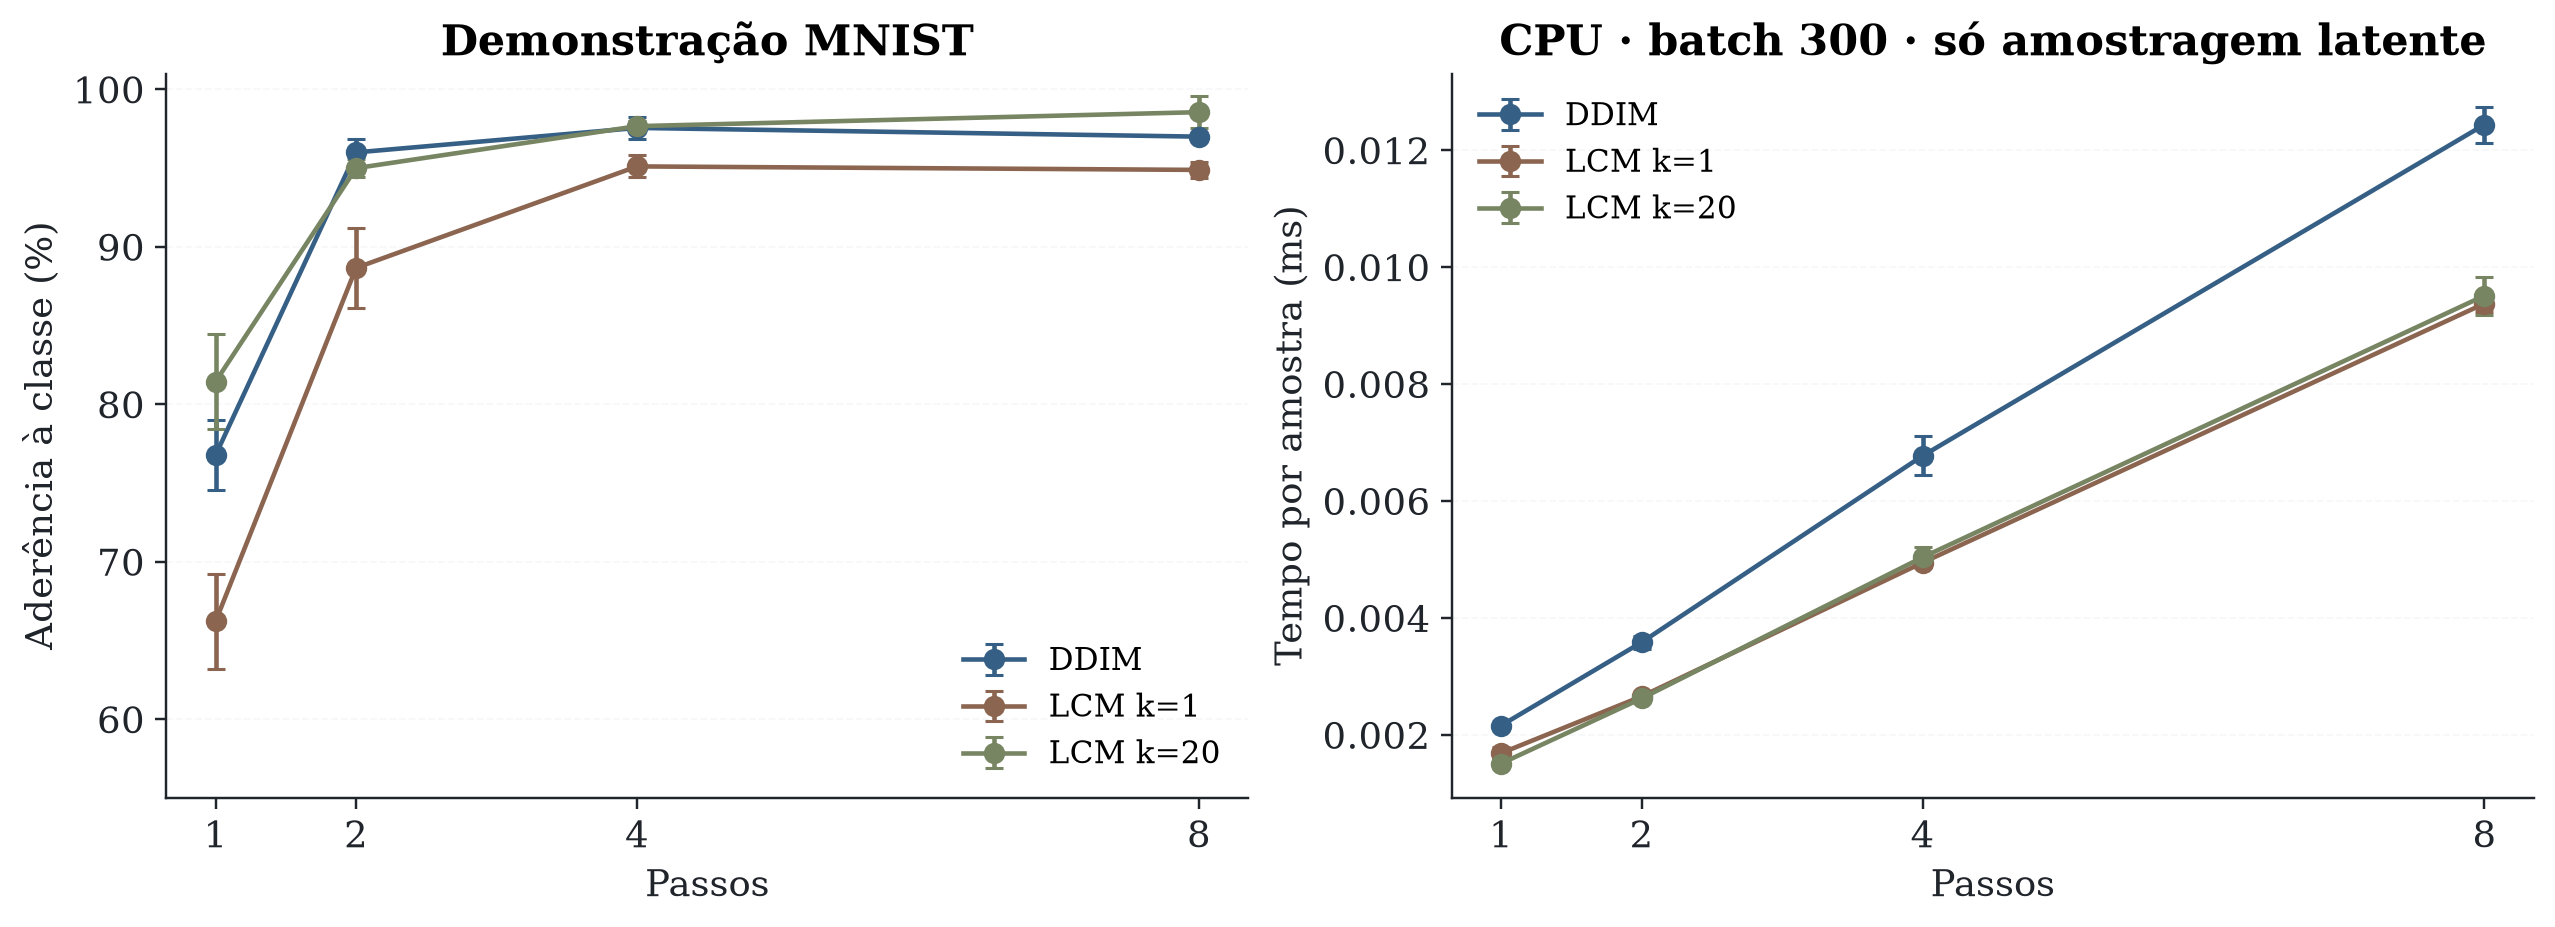

In [2]:
display(Image(filename=str(ROOT / 'assets/figures/local_results.png')))

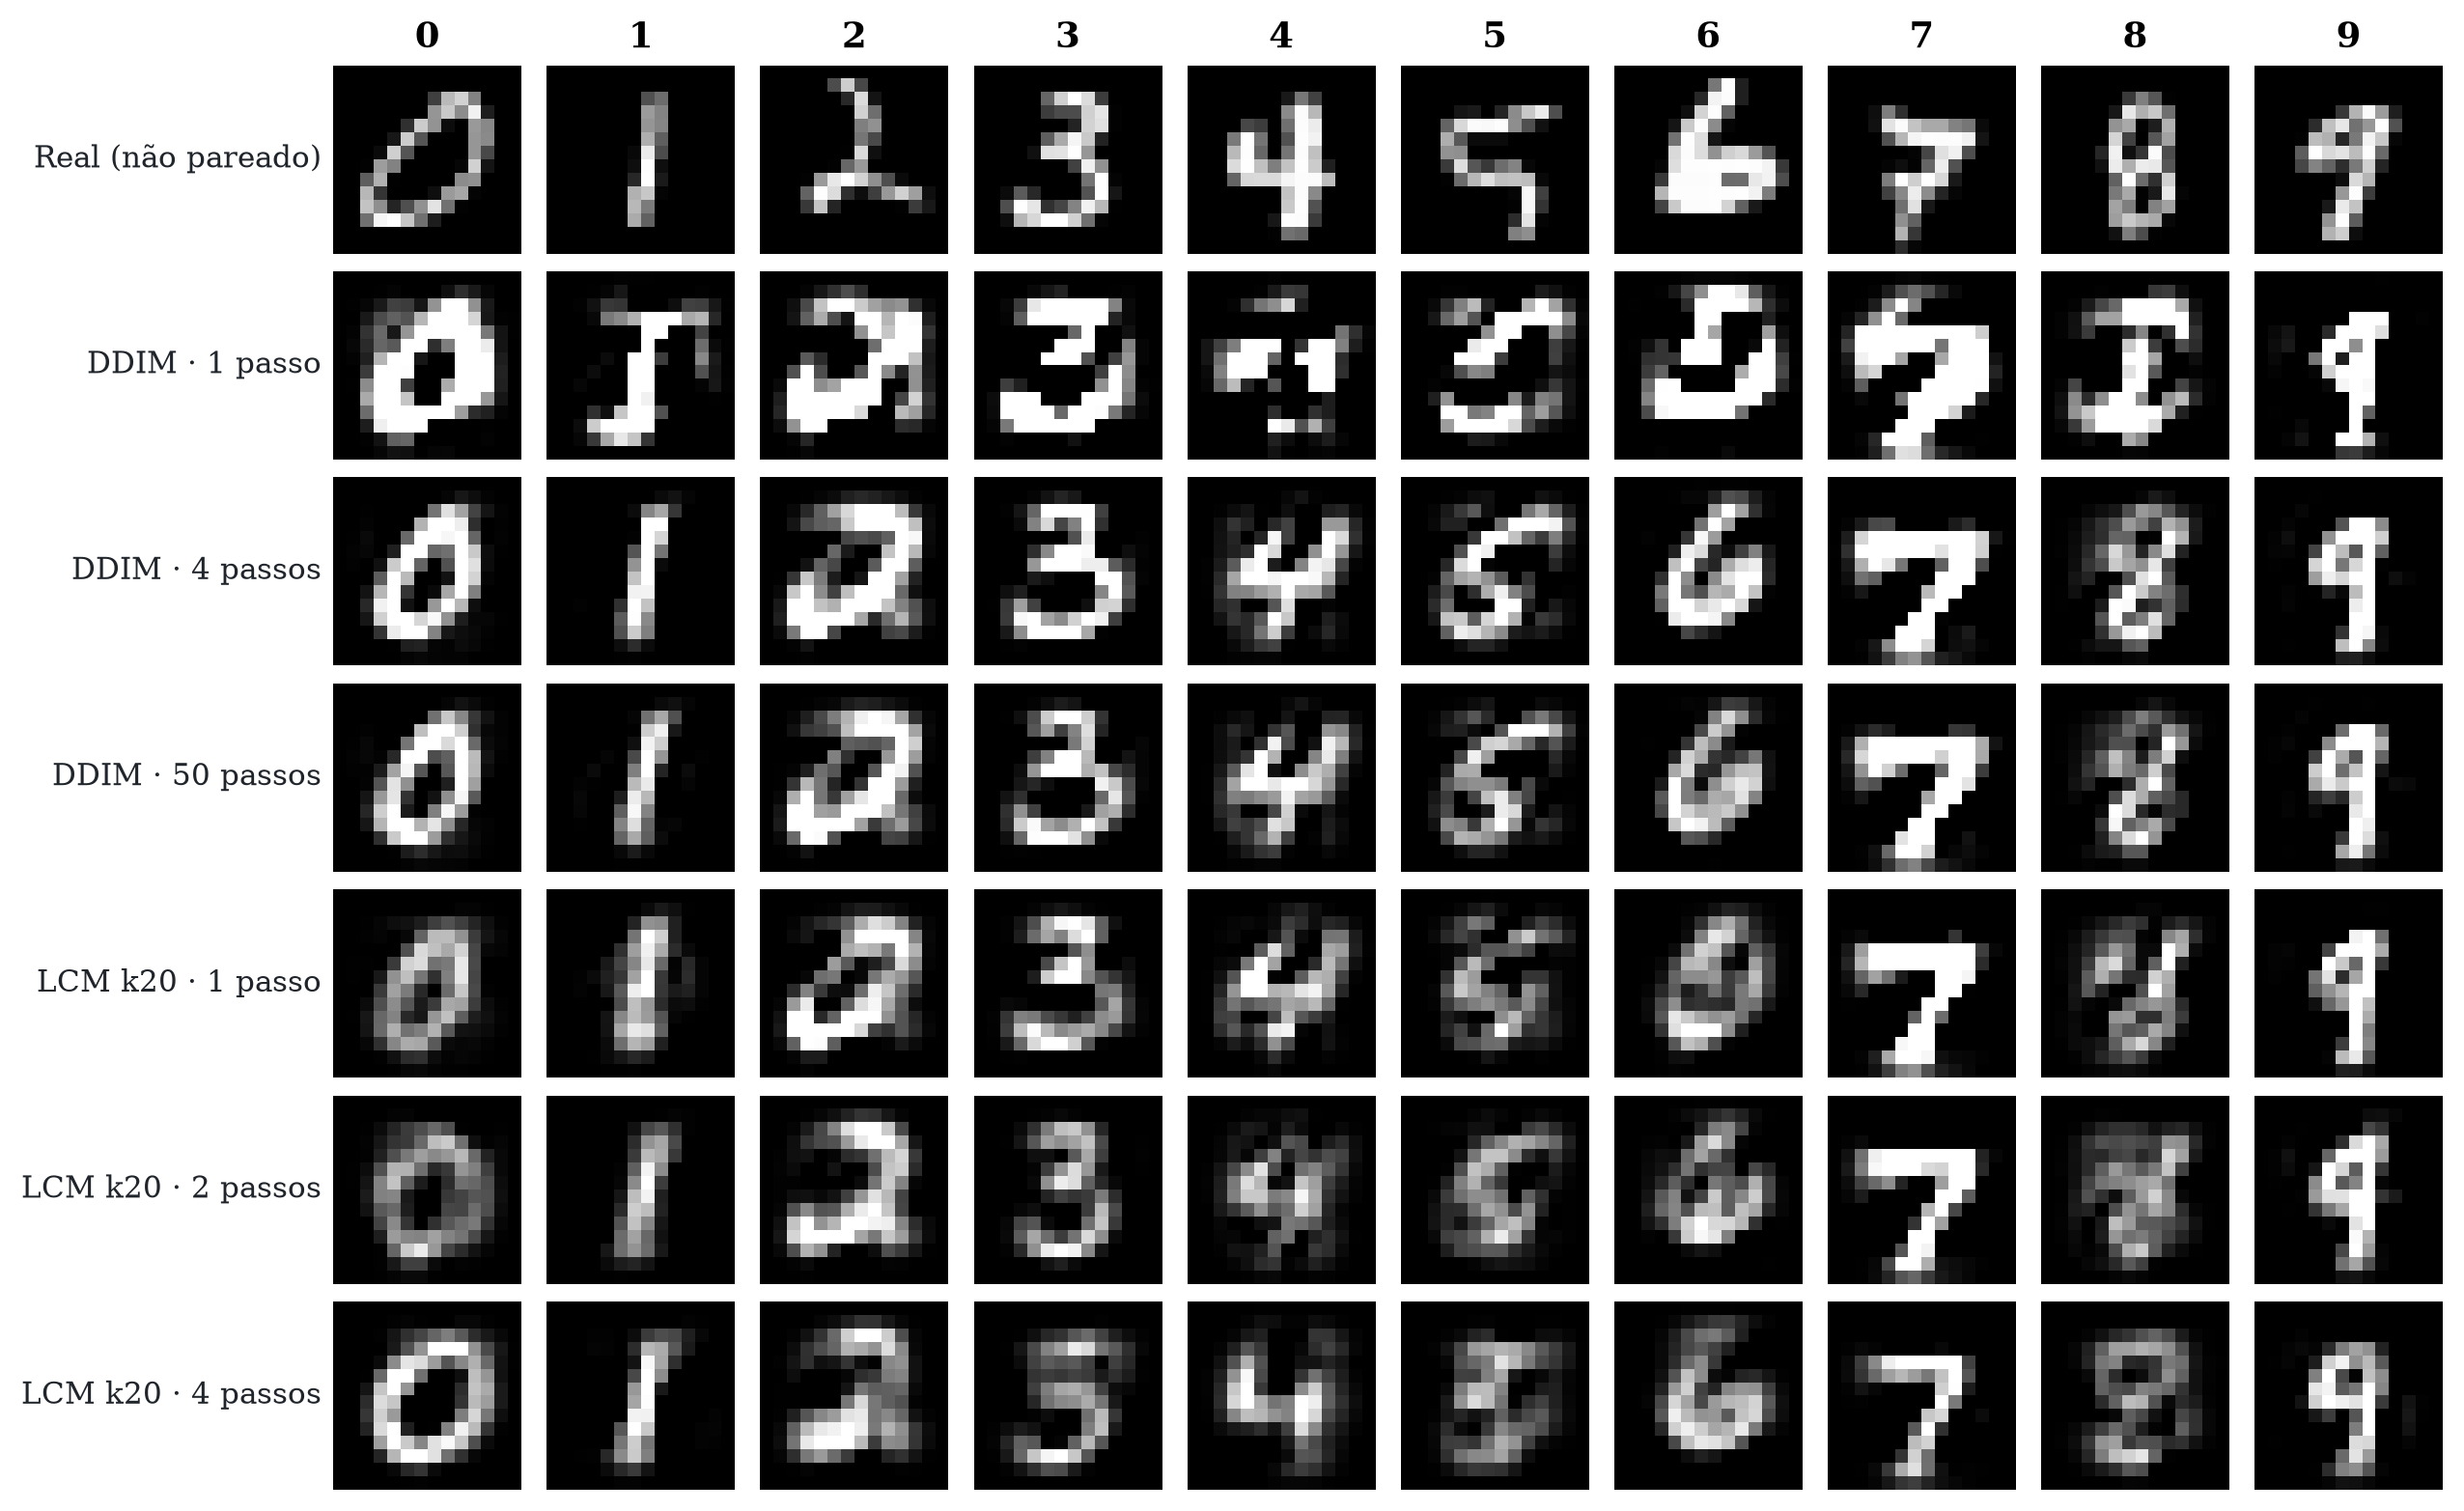

In [3]:
display(Image(filename=str(ROOT / 'assets/figures/generation_grid.png')))

In [4]:
rows = list(csv.DictReader((ROOT / 'experiments/results/metrics.csv').open()))
for method in ['ddim', 'lcm_k1', 'lcm_k20']:
    values = [float(r['class_agreement']) for r in rows if r['method']==method and int(r['steps'])==4]
    print(method, '4 passos:', np.mean(values), 'DP amostral:', np.std(values, ddof=1))
print('FID e CLIP locais: N/A — configuração experimental diferente')

ddim 4 passos: 0.9755555788675944 DP amostral: 0.006938880047449113
lcm_k1 4 passos: 0.9511110981305441 DP amostral: 0.006938880047449113
lcm_k20 4 passos: 0.9766666889190674 DP amostral: 0.0033333301544189453
FID e CLIP locais: N/A — configuração experimental diferente


# Auditoria metodológica

## Versão e fontes

O objeto de estudo é o PDF v1 de 06/10/2023, não uma revisão posterior. O
repositório oficial foi consultado na revisão
`a9ad79587cc8bd1e404ccd1a3056a3da969b2f62`. Também foram inspecionados o script
de treino e o scheduler LCM do Diffusers **v0.35.1**. Esse código posterior é
referência de implementação, não prova da configuração que produziu as tabelas
do preprint.

## Diferenças verificadas

| Tema | Paper v1 | Código/artefato público consultado | Consequência |
|---|---|---|---|
| Professor principal | SD2.1-Base/SD2.1 | README promove LCM_Dreamshaper_v7 e versões posteriores | Checkpoints distintos não reproduzem automaticamente Tabelas 1/2 |
| Orçamento | 100k iterações nas tabelas | Divulgação de 4k e 32 horas-GPU | Não atribuir todo resultado ao orçamento menor |
| Nome visual | “Dreamer-V7” no PDF | “Dreamshaper_v7” no README | Preservar grafias e registrar discrepância |
| EMA | 0,999943 | Default 0,95 no script Diffusers consultado | Defaults não são a receita do PDF |
| Otimizador | RAdam no Apêndice F | AdamW/8-bit AdamW no script consultado | Diferença de treinamento |
| Guidance | ω∈[2,14], combinação (1+ω)ε_c−ωε_∅ | Defaults w_min=5, w_max=15 e comentários com convenções a conferir | Inspecionar cálculo e embedding, não só ajuda de CLI |
| Perda | Distância d, incluindo quadrática | l2 ou Huber, default l2 no arquivo consultado | Registrar opção efetivamente usada |
| Boundary | Condições c_skip(0)=1, c_out(0)=0 | σ_data=0,5 e tempo discreto×10 no scheduler | Não assumir mesma escala com tempo normalizado |
| Avaliação | 30k imagens, ViT-g/14 | API de inferência não implementa todo protocolo de avaliação | Usar a pipeline não reproduz FID/CLIP |

O comentário de argumentos de guidance no script Diffusers afirma uma mudança
de convenção, enquanto o bloco de cálculo da predição guiada menciona a convenção
do paper. Isso exige atenção na integração. Neste seminário, a fórmula efetiva
é declarada explicitamente em todos os experimentos locais e não depende dessa API.
Não foi auditado o conteúdo numérico de pesos remotos, pois não foram baixados.

## Desvios deliberados da demonstração

| Componente | Paper | Demonstração executada |
|---|---|---|
| Imagem | RGB 512/768 | MNIST cinza 14×14 |
| Latente | VAE de SD | Autoencoder linear PCA, 32 dimensões, whitening |
| Condição | Texto CLIP | Classe 0–9 e classe nula |
| Backbone | U-Net de SD | MLP, duas camadas ocultas de 128 |
| Professor | Modelo pré-treinado de grande escala | Treinado localmente, 5000 updates DDPM |
| LCD | 100k updates | 5000 updates por k |
| Batch | 72/16 | 128 |
| Learning rate aluno | 8e-6 | 2e-4 |
| EMA | 0,999943 | 0,99 |
| Guidance treino | [2,14] | [0,2], avaliação ω=1 |
| Solver | DDIM, k=20 | DDIM, ablação k=1/20 |
| Tempos | Agenda de 1000, redução descrita no artigo | Índices inteiros com salto fixo, inclui zero exato |
| Coeficientes boundary | Formulação geral | Tempo normalizado×10, σ_data=0,5 |
| Métricas | FID/CLIP | Aderência à classe local, desvio latente, latência |
| Hardware | A100 | CPU, duas threads |

Os hiperparâmetros locais são escolhas didáticas fixadas na configuração, não
valores omitidos que teriam sido “recuperados” do paper.

## Comparabilidade e limites

O classificador de avaliação é treinado apenas no split de treino. Seu desempenho
no teste real é registrado no protocolo. Aderência de sintéticos pode exceder a
acurácia em reais porque os geradores produzem exemplos mais fáceis ou menos
diversos. Isso não prova fidelidade nem cobertura da distribuição.

O mesmo ruído inicial é usado entre métodos. LCM com vários passos acrescenta
novos ruídos, então a MSE contra DDIM-50 não compara trajetórias idênticas.
Ela quantifica desvio de um professor, não distância a um ground truth de geração.
MNIST não tem imagem real única associada a cada ruído inicial.

Há uma semente de treino por modelo e três sementes de geração. A média e o
desvio padrão entre gerações não representam incerteza de treinamento.
A latência mede apenas amostragem latente em batch de 300, sem decoder,
classificador e disco. Tempos curtos são sensíveis a ruído do sistema.
As medições não demonstram aceleração em GPU nem em Stable Diffusion.

Uma perda menor para k=1 não torna esse modelo melhor: pares próximos facilitam
a tarefa de consistência local sem assegurar boa previsão de longa distância.
Não comparar as escalas de perda de k diferentes como ranking de geradores.

## Ambiente e escopo de mudanças

O Python do `.venv` antigo aponta para uma instalação removida do VS Code.
O launcher identifica explicitamente essa condição e usa o Python 3.13 instalado
pelo uv com os pacotes existentes. Não corrige nem modifica o ambiente antigo.
`python-pptx` foi instalado isoladamente em `seminar_5/.deps`.
Um ambiente independente com `requirements.txt` é a opção portátil documentada.

A reprodução integral não foi tentada: o ambiente observado é CPU, sem CUDA,
e não há os checkpoints SD nem a coleta LAION necessários nesta pasta. O acesso
ao código oficial foi verificado. Não há alegação de indisponibilidade universal
de dados/pesos, apenas de ausência no experimento executado.


# DDPM para aumento SAR e comparação futura com LCM

## Evidência atual e nova direção

As entregas `project/initial_project.pdf` e, principalmente,
`project/second_part_project.pdf` descrevem segmentação de pistas de pouso em
SAR Sentinel-1. A entrega mais recente compara YOLOv8s-seg, YOLO11s-seg,
YOLOv8x-seg, YOLO11x-seg e SAM ajustado. Usa otimização Ray Tune para YOLO,
um estudo Optuna de 150 tentativas para SAM e ablações de pré-processamento e
aumento. O manuscrito destaca que diferenças de dados, transformações e
inferência limitam comparações causais entre arquiteturas.

Na entrega, o teste YOLO tem 115 imagens. IoU macro reportada é 22,33% para
YOLOv8x-seg e 24,56% para YOLO11x-seg após otimização. As variantes Small têm
26,61% e 28,24%, respectivamente. O valor histórico SAM é IoU 0,3769, com
protocolo distinto. A avaliação final no teste da nova configuração SAM escolhida
pela validação ainda é descrita como pendente no documento. Esses valores são
**reportados na entrega**, não recalculados nem validados nesta atividade.
Não os usar como um ranking conclusivo de arquiteturas.

**Orientação do usuário nesta sessão:** acrescentar DDPM para aumentar os dados
de treino, seguindo o princípio dos experimentos SAM, e posteriormente usar
LCM para comparação. Esta é uma nova direção planejada da pesquisa, não um
resultado já presente nos documentos. Não foi implementado nem treinado um
gerador SAR nesta atividade.

## Aplicabilidade

LCM é diretamente relevante como alternativa para acelerar um **gerador** de
dados sintéticos já treinado. Não substitui SAM/YOLO e não segmenta pistas por
si só. A cadeia proposta é:

```text
Treino SAR real + máscaras
          ↓
Professor DDPM condicionado em máscara
          ↓
Dados sintéticos pareados ──────────────────┐
          ↓                                │
Destilação por consistência                │ comparação
          ↓                                │ controlada
Gerador de consistência em 1–4 passos       │
          ↓                                │
Dados sintéticos pareados ──────────────────┘
          ↓
Mesmo segmentador SAM ou YOLO, mesmo protocolo
          ↓
Teste SAR real intocado: IoU, Dice, falsos positivos/negativos
```

É necessário primeiro definir como o DDPM fornecerá supervisão utilizável.
O caminho recomendado para o primeiro experimento é gerar a imagem SAR
**condicionada numa máscara conhecida**. A máscara permanece o rótulo somente
se a imagem gerada respeitar sua geometria. É preciso auditar esse alinhamento.
Gerar imagens sem condição e inventar uma máscara correspondente não constitui
um par supervisionado. Usar o próprio segmentador para pseudo-rotular sintéticos
introduz outra intervenção e possível reforço dos seus erros.

### Decisão arquitetural essencial

| Professor planejado | Comparador coerente | O que evitar |
|---|---|---|
| DDPM em pixels SAR | Consistency Distillation em pixels, com a mesma condição espacial | Chamar esse aluno de LCM, pois não há espaço latente |
| Difusão em latente SAR com autoencoder validado | LCD/LCM com mesmo encoder, decoder e condição | Comparar professores/dados distintos e atribuir toda diferença ao sampler |
| DDPM de pixels comparado a um LCM latente novo | Estudo de sistemas completos, com ablação do autoencoder | Tratar o estudo como mudança exclusiva de número de passos |

Portanto, DDPM não se converte automaticamente no LCM do artigo. A expressão
DDPM pode descrever a família de treinamento, mas é preciso registrar se ele
opera em pixels ou latentes. Para uma comparação limpa, destilar do **mesmo
professor adaptado ao domínio** é preferível a usar diretamente Dreamshaper.
O LCF do artigo é uma alternativa de adaptação futura, mas não resolve sozinho
a necessidade de condicionamento espacial por máscara e fidelidade SAR.

## Adaptações necessárias

- Preservar a representação SAR: polarização, escala de intensidade, recorte,
  resolução e normalização precisam ser iguais entre braços experimentais.
  Replicar uma banda em RGB não garante adequação física do modelo.
- Incorporar a máscara espacial ao gerador, por concatenação ou condicionador
  compatível. Essa extensão não é demonstrada pelo artigo LCM para SAR.
- Validar o autoencoder antes da destilação. Medir reconstrução na região da
  pista e preservação de largura/contorno, além de erro global.
- Usar apenas dados de treino no gerador, no autoencoder, na seleção de
  exemplos e na elaboração de máscaras condicionantes.
- Preservar máscaras com interpolação adequada, evitando que transforms de
  imagem e rótulo divirjam. Considerar speckle e estatísticas de fundo.
- Estabelecer política de aceitação dos pares em validação e mantê-la fixa.
  Registrar rejeições, pistas ausentes, alterações de largura e repetição.

## Experimento futuro A: validar aumento com DDPM

**Hipótese:** dados SAR sintéticos condicionados em máscara melhoram a
generalização do segmentador em imagens reais, sob orçamento de treino fixo.
O ganho não é assumido.

**Baseline:** primeiro, a configuração SAM escolhida pela validação, após
resolver a avaliação e congelar o protocolo. Um experimento separado pode usar
YOLO11s-seg ou outro modelo já estabelecido. Não selecionar o segmentador pelo
resultado deste experimento no teste.

**Braços:** real apenas, real com aumento convencional já estudado, e real com
dados DDPM. Definir previamente uma proporção, por exemplo 25% de sintéticos
por batch, como **configuração proposta**, não valor extraído do artigo.
Manter inicialização, número de atualizações, batches, transforms compartilhadas,
tratamento de máscaras e política de early stopping iguais.

**Dados:** auditar sobreposição geográfica e de cenas entre splits. Usar a
validação para selecionar gerador, filtros e proporção. O teste real de 115
imagens pode preservar a comparação histórica, desde que sua independência
seja auditada. Se houver imagens da mesma pista ou cena em splits diferentes,
é necessário definir uma avaliação por local adicional.

**Métricas:** IoU macro e Dice macro no teste real, métricas de contorno/largura,
FP/FN, resultados por pista/local. Registrar também custo para gerar cada par
aceito e taxa de rejeição. Não converter média IoU em média Dice pela fórmula
não linear aplicada à média.

**Critério de sucesso proposto:** ganho de pelo menos 1 ponto percentual de
IoU macro frente ao aumento convencional, sem queda material de Dice/contorno,
com intervalo de confiança do ganho acima de zero quando o tamanho amostral
permitir. O limiar é uma proposta a pré-registrar, não uma previsão.
Usar pelo menos três sementes de treino pareadas e bootstrap por pista/local,
não tratar pixels como observações independentes.

## Experimento futuro B: DDPM versus consistência/LCM

**Hipótese:** a destilação reduz o custo por par sintético aceito e preserva
o benefício downstream do DDPM dentro de uma margem predefinida.

**Método:** congelar o professor DDPM aprovado no experimento A. Caso ele opere
em latentes, destilar um LCM com as mesmas condições espaciais. Caso opere em
pixels, o primeiro comparador será um modelo de consistência em pixels.
Medir 1, 2 e 4 passos do aluno, um DDIM de poucos passos do mesmo professor e o
sampler DDPM de referência. O DDIM controla quanto do ganho vem simplesmente
de reduzir passos sem destilação.

**Dois controles complementares:**

1. Mesmo número de pares sintéticos aceitos, máscaras condicionantes, proporção
   real/sintético e número de updates do segmentador. Isola qualidade/utilidade.
2. Mesmo tempo disponível para geração. Permite comparar o uso de maior volume,
   mas constitui um segundo experimento e deve ser relatado separadamente.

**Métricas:** mesmas métricas downstream do experimento A, latência total
incluindo encoder/decoder e filtragem, throughput, pico de memória, tempo e
custo de destilação, taxa de aceitação e diversidade de pares.
Usar aquecimento e repetições, mesmo hardware e precisão numérica.
Contar chamadas condicionadas e não condicionadas explicitamente.

**Critério de sucesso proposto:** o limite inferior do intervalo pareado
LCM−DDPM em IoU macro deve ficar acima de −1 ponto percentual, com redução de
pelo menos 2× no custo de geração por par aceito. A margem de 1 p.p. e o fator
2× são escolhas de protocolo a discutir, não achados do seminário.
Contabilizar o custo de destilação:
\[
N_{\rm equilíbrio}=
\frac{C_{\rm destilação}}{c_{\rm DDPM}-c_{\rm aluno}},
\]
válido quando o denominador é positivo e os custos são definidos na mesma
unidade por par aceito. Se o volume pretendido for menor, o aluno pode não
compensar economicamente.

## Conclusão crítica

A nova direção torna LCM um candidato pertinente, condicionado ao sucesso do
gerador DDPM e à preservação das máscaras. O primeiro problema científico é a
utilidade de dados SAR sintéticos. O segundo é acelerar a geração preservando
essa utilidade. Resultados em MNIST ou FID/CLIP em imagens naturais não
respondem a nenhuma dessas perguntas em SAR. A demonstração deste seminário
fornece uma implementação verificável de LCD e um protocolo para investigá-las.
